# customer churn analysis

in this file we are going to connect the sql database and perform some analysis on the customer churn data. We will use Python libraries such as pandas, numpy, and matplotlib for data manipulation and visualization.
- The goal is to identify patterns and factors that contribute to customer churn, which can help in developing strategies to retain customers.

In [2]:
#import libaries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sqlite3


# data source

In [3]:
# import database
conn = sqlite3.connect('customer_churn.db')  #connection BUILDING

sql_query = """ SELECT name
                FROM sqlite_master
                WHERE type='table'
            """

tables = pd.read_sql(sql_query, conn)  
print("tables", tables)

print("============================================================")

# create dataframe for each table
for table_name in tables['name']:
    df = pd.read_sql(f"SELECT * FROM {table_name}", conn)
    globals()[f"df_{table_name}"] = df   #globals() function to create a variable with the name of the table
    print(f"Created dataframe: df_{table_name}")
    
# connection close
conn.close()

tables               name
0      db_customer
1  db_subscription
2       db_support
Created dataframe: df_db_customer
Created dataframe: df_db_subscription
Created dataframe: df_db_support


In [4]:
#print table names and columns name
conn = sqlite3.connect('customer_churn.db')  #connection BUILDING

for table_name in tables['name']:
    print(f"\nTable Name: {table_name}")
    # Get column names
    columns_query = f"PRAGMA table_info({table_name});" #pargma a command to get the column names of a table
    columns = pd.read_sql(columns_query, conn)
    print("Columns:")
    print(columns['name'].tolist()) # print column names as list

    # connection close
conn.close()


Table Name: db_customer
Columns:
['customerid', 'name', 'country', 'state', 'gender', 'dob', 'interests', 'pincode']

Table Name: db_subscription
Columns:
['customerid', 'subscription_start_date', 'subscription_type', 'renewal_date', 'plan_type', 'contract_type', 'cancellation_date', 'cancellation_reason', 'monthly_charges', 'cltv', 'churn_score']

Table Name: db_support
Columns:
['customerid', 'complaint_date', 'escalations', 'csat_score', 'col_1', 'comment']


# data cleaning

In [5]:
df_db_customer.head(5)

,customerid,name,country,state,gender,dob,interests,pincode
0,0002-ORFBO,keshav,India,Maharashtra,Male,1982-04-12 00:00:00,travel,None
1,0003-MKNFE,raghav,India,Karnataka,Male,1995-11-23 00:00:00,NaN,None
2,0004-TLHLJ,lalita,India,Delhi,Female,1978-02-15 00:00:00,movie,None
3,0011-IGKFF,mohan,India,Nagaland,Male,2001-08-30 00:00:00,NaN,None
4,0013-EXCHZ,mira,India,Delhi,Female,1990-05-05 00:00:00,drama,None


In [6]:
df_db_customer.tail()

,customerid,name,country,state,gender,dob,interests,pincode
16,0020-JDNXP,rikim,India,Meghalaya,Female,1994-08-19 00:00:00,NaN,None
17,0021-IKXGC,vishakha,India,Rajasthan,Female,2000-09-02 00:00:00,NaN,None
18,0022-TCJCI,raghvendra,India,Telangana,Male,1983-12-30 00:00:00,NaN,None
19,0023-HGHWL,rishabh,India,Uttar Pradesh,Men,1991-05-14 00:00:00,NaN,None
20,0023-UYUPN,sudevi,India,Maharashtra,Women,1977-10-06 00:00:00,NaN,None


In [7]:
df_db_customer.info()

<class 'pandas.DataFrame'>
RangeIndex: 21 entries, 0 to 20
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   customerid  21 non-null     str   
 1   name        21 non-null     str   
 2   country     18 non-null     str   
 3   state       21 non-null     str   
 4   gender      21 non-null     str   
 5   dob         21 non-null     str   
 6   interests   4 non-null      str   
 7   pincode     0 non-null      object
dtypes: object(1), str(7)
memory usage: 1.4+ KB


1. Total entries: 21
2. country has only 18 entries , so there is null 
3. intrests 4 , so drop this 
4. rename col " name" ==> customer_name
5. change data type of "date_of_birth" to datetime
6. fix gender column to have only 2 values male and female


In [8]:
# rename
df_db_customer.rename(columns ={'name':'customer_name'}, inplace = True) #inplace= true updates df
df_db_customer.head(5)

,customerid,customer_name,country,state,gender,dob,interests,pincode
0,0002-ORFBO,keshav,India,Maharashtra,Male,1982-04-12 00:00:00,travel,None
1,0003-MKNFE,raghav,India,Karnataka,Male,1995-11-23 00:00:00,NaN,None
2,0004-TLHLJ,lalita,India,Delhi,Female,1978-02-15 00:00:00,movie,None
3,0011-IGKFF,mohan,India,Nagaland,Male,2001-08-30 00:00:00,NaN,None
4,0013-EXCHZ,mira,India,Delhi,Female,1990-05-05 00:00:00,drama,None


In [9]:
#  drop columns ( intrest and pincode)
df_db_customer.drop(['interests', 'pincode'], axis=1, inplace=True) #axis=1 means drop column, axis=0 means drop row
df_db_customer.head(5)

,customerid,customer_name,country,state,gender,dob
0,0002-ORFBO,keshav,India,Maharashtra,Male,1982-04-12 00:00:00
1,0003-MKNFE,raghav,India,Karnataka,Male,1995-11-23 00:00:00
2,0004-TLHLJ,lalita,India,Delhi,Female,1978-02-15 00:00:00
3,0011-IGKFF,mohan,India,Nagaland,Male,2001-08-30 00:00:00
4,0013-EXCHZ,mira,India,Delhi,Female,1990-05-05 00:00:00


In [10]:
#  change data type of column -dob
df_db_customer['dob'] = pd.to_datetime(df_db_customer['dob'])


In [11]:
df_db_customer.info()

<class 'pandas.DataFrame'>
RangeIndex: 21 entries, 0 to 20
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   customerid     21 non-null     str           
 1   customer_name  21 non-null     str           
 2   country        18 non-null     str           
 3   state          21 non-null     str           
 4   gender         21 non-null     str           
 5   dob            21 non-null     datetime64[us]
dtypes: datetime64[us](1), str(5)
memory usage: 1.1 KB


In [12]:
#  data standardization - gender

df_db_customer['gender'].unique()

<StringArray>
['Male', 'Female', 'Women', 'Men']
Length: 4, dtype: str

In [13]:
df_db_customer['gender'] = df_db_customer['gender'].replace({'Men' : 'Male', 'Women' : 'Female'})
df_db_customer['gender'].unique()

<StringArray>
['Male', 'Female']
Length: 2, dtype: str

In [14]:
# fix missing values - country
df_db_customer['country'].isna().sum() # check missing values

np.int64(3)

In [15]:
df_db_customer[df_db_customer['country'].isna()]

,customerid,customer_name,country,state,gender,dob
5,0013-MHZWF,durga,NaN,Delhi,Female,1988-12-10
8,0015-UOCOJ,maya,NaN,Kathmandu,Female,1985-07-07
12,0018-NYROU,chitra,NaN,Telangana,Female,2004-12-01


In [16]:
df_db_customer['country'].fillna("jani na")

0       India
1       India
2       India
3       India
4       India
5     jani na
6       India
7       India
8     jani na
9       Nepal
10      India
11      India
12    jani na
13      India
14      India
15      India
16      India
17      India
18      India
19      India
20      India
Name: country, dtype: str

In [17]:
df_db_customer[['country','state']]

,country,state
0,India,Maharashtra
1,India,Karnataka
2,India,Delhi
3,India,Nagaland
4,India,Delhi
5,NaN,Delhi
6,India,Meghalaya
7,India,Rajasthan
8,NaN,Kathmandu
9,Nepal,Kathmandu


In [18]:
state_country_mapping=df_db_customer.dropna(subset=['country']).set_index('state')['country'].to_dict()

df_db_customer['country'] = df_db_customer['country'].fillna(df_db_customer['state'].map(state_country_mapping))

In [19]:
df_db_customer[df_db_customer['country'].isna()]
#  no more missing values in country column

,customerid,customer_name,country,state,gender,dob


now customer table is ready to use , we have more 2 tables 

In [20]:
df_db_subscription.head(5)

,customerid,subscription_start_date,subscription_type,renewal_date,plan_type,contract_type,cancellation_date,cancellation_reason,monthly_charges,cltv,churn_score
0,0002-ORFBO,2021-03-15,Refferal,2025-03-15,Standard,Annual,NaN,NaN,13.99,627,12
1,0003-MKNFE,2020-08-01,Paid,2024-08-01,Premium,Annual,2024-09-10,Switched to competitor,12.99,1150,91
2,0004-TLHLJ,2022-11-20,Organic,2025-11-20,Basic,Monthly,NaN,NaN,6.99,210,34
3,0011-IGKFF,2019-05-10,Paid,2025-05-10,Premium,Annual,NaN,NaN,22.99,1725,8
4,0013-EXCHZ,2023-01-05,Refferal,2024-01-05,Standard,Monthly,2024-02-28,Too expensive,13.99,195,88


In [21]:
df_db_subscription.info()

<class 'pandas.DataFrame'>
RangeIndex: 21 entries, 0 to 20
Data columns (total 11 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   customerid               21 non-null     str    
 1   subscription_start_date  21 non-null     str    
 2   subscription_type        21 non-null     str    
 3   renewal_date             21 non-null     str    
 4   plan_type                21 non-null     str    
 5   contract_type            21 non-null     str    
 6   cancellation_date        6 non-null      str    
 7   cancellation_reason      6 non-null      str    
 8   monthly_charges          21 non-null     float64
 9   cltv                     21 non-null     int64  
 10  churn_score              21 non-null     int64  
dtypes: float64(1), int64(2), str(8)
memory usage: 1.9 KB


1. change data type of date to datetime

In [22]:
date_col = [ "subscription_start_date","renewal_date","cancellation_date"]
df_db_subscription[date_col] = df_db_subscription[date_col].apply(pd.to_datetime)
df_db_subscription.info()

<class 'pandas.DataFrame'>
RangeIndex: 21 entries, 0 to 20
Data columns (total 11 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   customerid               21 non-null     str           
 1   subscription_start_date  21 non-null     datetime64[us]
 2   subscription_type        21 non-null     str           
 3   renewal_date             21 non-null     datetime64[us]
 4   plan_type                21 non-null     str           
 5   contract_type            21 non-null     str           
 6   cancellation_date        6 non-null      datetime64[us]
 7   cancellation_reason      6 non-null      str           
 8   monthly_charges          21 non-null     float64       
 9   cltv                     21 non-null     int64         
 10  churn_score              21 non-null     int64         
dtypes: datetime64[us](3), float64(1), int64(2), str(5)
memory usage: 1.9 KB


df_db_subscription is cleaned and ready to use

In [23]:
df_db_support.head(5)

,customerid,complaint_date,escalations,csat_score,col_1,comment
0,0003-MKNFE,2024-08-28 00:00:00,N,60,None,service issue
1,0003-MKNFE,2024-08-28 00:00:00,Y,10,None,demaned refund
2,0013-EXCHZ,2024-01-20 00:00:00,Y,20,None,NaN
3,0013-MHZWF,2025-03-18 00:00:00,N,90,None,guidance to renew
4,0013-SMEOE,2024-11-01 00:00:00,N,30,None,NaN


In [24]:
df_db_support.info()

<class 'pandas.DataFrame'>
RangeIndex: 9 entries, 0 to 8
Data columns (total 6 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   customerid      9 non-null      str   
 1   complaint_date  9 non-null      str   
 2   escalations     9 non-null      str   
 3   csat_score      9 non-null      int64 
 4   col_1           0 non-null      object
 5   comment         4 non-null      str   
dtypes: int64(1), object(1), str(4)
memory usage: 564.0+ bytes


1. col_1  is garbage , so drop this
2. commemnt is not needed , so drop this
3. chnage data type to datetime of complaint_date

In [25]:
df_db_support.drop(columns=['col_1','comment'],inplace=True)

In [26]:
df_db_support['complaint_date'] = pd.to_datetime(df_db_support['complaint_date'])
df_db_support.info()

<class 'pandas.DataFrame'>
RangeIndex: 9 entries, 0 to 8
Data columns (total 4 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   customerid      9 non-null      str           
 1   complaint_date  9 non-null      datetime64[us]
 2   escalations     9 non-null      str           
 3   csat_score      9 non-null      int64         
dtypes: datetime64[us](1), int64(1), str(2)
memory usage: 420.0 bytes


# feature engineering

In [27]:
# created a new col using existing col - churn_flag
df_db_subscription['churn_flag'] = np.where(df_db_subscription['cancellation_date'].notna(), 1, 0) #if cancellation date is not null then churn_flag = 1 else 0
df_db_subscription.head(5)

,customerid,subscription_start_date,subscription_type,renewal_date,plan_type,contract_type,cancellation_date,cancellation_reason,monthly_charges,cltv,churn_score,churn_flag
0,0002-ORFBO,2021-03-15,Refferal,2025-03-15,Standard,Annual,NaT,NaN,13.99,627,12,0
1,0003-MKNFE,2020-08-01,Paid,2024-08-01,Premium,Annual,2024-09-10,Switched to competitor,12.99,1150,91,1
2,0004-TLHLJ,2022-11-20,Organic,2025-11-20,Basic,Monthly,NaT,NaN,6.99,210,34,0
3,0011-IGKFF,2019-05-10,Paid,2025-05-10,Premium,Annual,NaT,NaN,22.99,1725,8,0
4,0013-EXCHZ,2023-01-05,Refferal,2024-01-05,Standard,Monthly,2024-02-28,Too expensive,13.99,195,88,1


In [28]:
df = (df_db_subscription
 .merge(df_db_customer, on='customerid', how='left')
 .merge(df_db_support, on='customerid', how='left'))

In [29]:
df.shape

(23, 20)

20 cols and 23 rows in the final dataset after merging all the tables. but i had 21 rows in subcribtion table, so there is one row missing after merging. we will check the missing row and find out the reason for that.

In [30]:
df_db_subscription.shape

(21, 12)

some where we have duplicate records , so we have to find out now 

In [31]:
df_db_subscription['customerid'].nunique() # 21 unique customers in subscription table

21

In [32]:
df_db_customer['customerid'].nunique() # 21 unique customers in customer table

21

In [33]:
df_db_support['customerid'].nunique()

7

In [34]:
df_db_support['customerid'].size  # 2 extra rows in support table, means 2 customers have multiple complaints

9

In [35]:
df_db_support

,customerid,complaint_date,escalations,csat_score
0,0003-MKNFE,2024-08-28,N,60
1,0003-MKNFE,2024-08-28,Y,10
2,0013-EXCHZ,2024-01-20,Y,20
3,0013-MHZWF,2025-03-18,N,90
4,0013-SMEOE,2024-11-01,N,30
5,0017-IUDMW,2024-04-10,Y,25
6,0019-EFAEP,2024-09-27,Y,30
7,0022-TCJCI,2024-09-13,Y,10
8,0022-TCJCI,2024-09-14,N,90


so there is one big problem , in support table customer can rise multiple compline and this is storeing multiple times , so i have to make it unique for each customer. we will group by customer_id and take the latest complaint date for each customer.

In [36]:
df_db_support['complaint_count'] = df_db_support.groupby('customerid')['customerid'].transform('count') #if a customer has multiple complaints, it will return the count of complaints for that customer

In [37]:
df_db_support

,customerid,complaint_date,escalations,csat_score,complaint_count
0,0003-MKNFE,2024-08-28,N,60,2
1,0003-MKNFE,2024-08-28,Y,10,2
2,0013-EXCHZ,2024-01-20,Y,20,1
3,0013-MHZWF,2025-03-18,N,90,1
4,0013-SMEOE,2024-11-01,N,30,1
5,0017-IUDMW,2024-04-10,Y,25,1
6,0019-EFAEP,2024-09-27,Y,30,1
7,0022-TCJCI,2024-09-13,Y,10,2
8,0022-TCJCI,2024-09-14,N,90,2


In [38]:
# now thake letest complaint for each customer
df_db_support = df_db_support.sort_values('complaint_date').drop_duplicates('customerid',keep='last')

In [39]:
df_db_support['customerid'].size

7

In [40]:
#  now merge all 3 tabels again after fixing the support table
df = (df_db_subscription
 .merge(df_db_customer, on='customerid', how='left')
 .merge(df_db_support, on='customerid', how='left'))

In [41]:
df.shape  # join succese full 21 rows 

(21, 21)

In [42]:
df.to_csv('exported_churn_data.csv', index=False)  # export to csv file

# DATA ANALYSIS

In [43]:
#1. churn rate

In [44]:
df.columns

Index(['customerid', 'subscription_start_date', 'subscription_type',
       'renewal_date', 'plan_type', 'contract_type', 'cancellation_date',
       'cancellation_reason', 'monthly_charges', 'cltv', 'churn_score',
       'churn_flag', 'customer_name', 'country', 'state', 'gender', 'dob',
       'complaint_date', 'escalations', 'csat_score', 'complaint_count'],
      dtype='str')

In [45]:
churn_rate = df['churn_flag'].mean()*100  # arounf 28.57% user are churned
print(f"Churn Rate: {churn_rate:.2f}%")

Churn Rate: 28.57%


In [46]:
#2 Retention Rate 

retention_rate = 100 - churn_rate
print(f"Retention Rate: {retention_rate:.2f}%")

Retention Rate: 71.43%


if we have 100 user next month approx 28 user will leave us 

In [47]:
df.head(2)

,customerid,subscription_start_date,subscription_type,renewal_date,plan_type,contract_type,cancellation_date,cancellation_reason,monthly_charges,cltv,...,churn_flag,customer_name,country,state,gender,dob,complaint_date,escalations,csat_score,complaint_count
0,0002-ORFBO,2021-03-15,Refferal,2025-03-15,Standard,Annual,NaT,NaN,13.99,627,...,0,keshav,India,Maharashtra,Male,1982-04-12,NaT,NaN,NaN,NaN
1,0003-MKNFE,2020-08-01,Paid,2024-08-01,Premium,Annual,2024-09-10,Switched to competitor,12.99,1150,...,1,raghav,India,Karnataka,Male,1995-11-23,2024-08-28,Y,10.0,2.0


In [48]:
#  churn by plan type
churn_by_plan = df.groupby('plan_type')['churn_flag'].mean().mul(100).round(2).reset_index(name='churn_rate_pct')
print(churn_by_plan)


  plan_type  churn_rate_pct
0     Basic           60.00
1   Premium           14.29
2  Standard           22.22


so mainly basic plan users are leaving us and they are not happy with our services. we have to improve our services for basic plan users to retain them.

letter i will do this 

In [49]:
# churn by state + sum(revenue) and count of users
# churn by subscription type + sum (revenue) and count of users


In [50]:
df.columns

Index(['customerid', 'subscription_start_date', 'subscription_type',
       'renewal_date', 'plan_type', 'contract_type', 'cancellation_date',
       'cancellation_reason', 'monthly_charges', 'cltv', 'churn_score',
       'churn_flag', 'customer_name', 'country', 'state', 'gender', 'dob',
       'complaint_date', 'escalations', 'csat_score', 'complaint_count'],
      dtype='str')

In [51]:
#avg revenue per user 
arpu = df['monthly_charges'].mean()  # avg revenue per user is 18.84
print(f"Average Revenue Per User (ARPU): {arpu:.2f}")

Average Revenue Per User (ARPU): 18.85


In [52]:
df.head(2)

,customerid,subscription_start_date,subscription_type,renewal_date,plan_type,contract_type,cancellation_date,cancellation_reason,monthly_charges,cltv,...,churn_flag,customer_name,country,state,gender,dob,complaint_date,escalations,csat_score,complaint_count
0,0002-ORFBO,2021-03-15,Refferal,2025-03-15,Standard,Annual,NaT,NaN,13.99,627,...,0,keshav,India,Maharashtra,Male,1982-04-12,NaT,NaN,NaN,NaN
1,0003-MKNFE,2020-08-01,Paid,2024-08-01,Premium,Annual,2024-09-10,Switched to competitor,12.99,1150,...,1,raghav,India,Karnataka,Male,1995-11-23,2024-08-28,Y,10.0,2.0


In [55]:
# avg customer tenure 
#count of days user has used our service : cancelation date else current date

today = pd.Timestamp.today()
#  If the user has cancelled, use the cancellation date; otherwise, use the current date
df['tenure_days'] = np.where(
        df['cancellation_date'].notna(),
        (df['cancellation_date'] - df['subscription_start_date']).dt.days,  #dt.days gives the number of days between two dates
        (today - df['subscription_start_date']).dt.days

)
avg_tenur = df['tenure_days'].mean()
print(f"Average Customer Tenure: {round(avg_tenur)} days")

Average Customer Tenure: 1575 days


tenure analysis to see how long customers are staying with us before they churn. This can help us identify if there is a specific time period where customers are more likely to leave.

In [60]:
# revune at risk - revenue lost due to churned customers

revenue_at_risk = df.loc[df['churn_flag'] == 1 , 'monthly_charges'].sum()  
print(f"Revenue at Risk (Rs 'k'): {revenue_at_risk:.2f}")

Revenue at Risk (Rs 'k'): 73.94


revenue loss 73.94 k


In [61]:
df.head(2)

,customerid,subscription_start_date,subscription_type,renewal_date,plan_type,contract_type,cancellation_date,cancellation_reason,monthly_charges,cltv,...,customer_name,country,state,gender,dob,complaint_date,escalations,csat_score,complaint_count,tenure_days
0,0002-ORFBO,2021-03-15,Refferal,2025-03-15,Standard,Annual,NaT,NaN,13.99,627,...,keshav,India,Maharashtra,Male,1982-04-12,NaT,NaN,NaN,NaN,2060.0
1,0003-MKNFE,2020-08-01,Paid,2024-08-01,Premium,Annual,2024-09-10,Switched to competitor,12.99,1150,...,raghav,India,Karnataka,Male,1995-11-23,2024-08-28,Y,10.0,2.0,1501.0


In [ ]:
# ESCALATION RATE -  how many customers have raised a complaint and how many of them have churned 

escalation_rate = (df['escalations'] == 'Y').mean() *100
print(f"Escalation Rate: {escalation_rate:.2f}%")


Escalation Rate: 19.05%


### how to decide which things i have to analyse , we have to study the data set and understand the business context. We can look at various factors such as customer demographics, subscription plans, usage patterns, and support interactions to identify potential reasons for churn. Additionally, we can use statistical methods and machine learning models to predict churn and identify key drivers. different kpis for churn analysis can be considered such as churn rate, retention rate, customer lifetime value, and customer satisfaction scores. By analyzing these KPIs, we can gain insights into customer behavior and make data-driven decisions to improve customer retention.

In [69]:
# avg complaint rate per user - how many complaints have been raised by each customer on average

avg_complaint = df['complaint_count'].sum() / df['customerid'].nunique()  # total complaints / total unique customers
print(f"Average Complaint Rate per User: {avg_complaint:.2f}")

Average Complaint Rate per User: 0.43


In [73]:
# corrlation between escalation and churn - how many customers have raised a complaint and how many of them have churned

df[["customerid","escalations" , "churn_flag"]].dropna()

# escalation in string 
df['escalations'] = np.where(df['escalations'] == 'Y', 1, 0)  # if escalation is Y then 1 else 0

In [75]:
df.head(2)

,customerid,subscription_start_date,subscription_type,renewal_date,plan_type,contract_type,cancellation_date,cancellation_reason,monthly_charges,cltv,...,customer_name,country,state,gender,dob,complaint_date,escalations,csat_score,complaint_count,tenure_days
0,0002-ORFBO,2021-03-15,Refferal,2025-03-15,Standard,Annual,NaT,NaN,13.99,627,...,keshav,India,Maharashtra,Male,1982-04-12,NaT,0,NaN,NaN,2060.0
1,0003-MKNFE,2020-08-01,Paid,2024-08-01,Premium,Annual,2024-09-10,Switched to competitor,12.99,1150,...,raghav,India,Karnataka,Male,1995-11-23,2024-08-28,1,10.0,2.0,1501.0


In [79]:
# now find coorelation between escalation and churn
corr_df = df[["escalations" , "churn_flag"]].dropna()
correlation = corr_df['escalations'].corr(df['churn_flag'])
print(f"Correlation between Escalation and Churn: {correlation:.2f}")

Correlation between Escalation and Churn: 0.77


corelation is 0.77 , so there is a strong positive correlation between the features we are analyzing and customer churn. This indicates that as certain factors increase, the likelihood of churn also increases. We can use this information to prioritize areas for improvement and develop targeted strategies to reduce churn.

In [80]:
# churn score
df['churn_score'].head()

0    12
1    91
2    34
3     8
4    88
Name: churn_score, dtype: int64

if churn score is <= 70 the user will churn 

In [81]:
#  churn risk  - create a col using existing col 
conditions = [
    (df['churn_score'] < 50),
    (df['churn_score'] >= 50) & (df['churn_score'] < 70), 
    (df['churn_score'] >= 70), 
]  # all condition in a list

choices = ['low', 'medium', 'high']  # all choices in a list

df['churn_risk'] = np.select(conditions,choices, default='unknown')

In [82]:
df.head()

,customerid,subscription_start_date,subscription_type,renewal_date,plan_type,contract_type,cancellation_date,cancellation_reason,monthly_charges,cltv,...,country,state,gender,dob,complaint_date,escalations,csat_score,complaint_count,tenure_days,churn_risk
0,0002-ORFBO,2021-03-15,Refferal,2025-03-15,Standard,Annual,NaT,NaN,13.99,627,...,India,Maharashtra,Male,1982-04-12,NaT,0,NaN,NaN,2060.0,low
1,0003-MKNFE,2020-08-01,Paid,2024-08-01,Premium,Annual,2024-09-10,Switched to competitor,12.99,1150,...,India,Karnataka,Male,1995-11-23,2024-08-28,1,10.0,2.0,1501.0,high
2,0004-TLHLJ,2022-11-20,Organic,2025-11-20,Basic,Monthly,NaT,NaN,6.99,210,...,India,Delhi,Female,1978-02-15,NaT,0,NaN,NaN,1445.0,low
3,0011-IGKFF,2019-05-10,Paid,2025-05-10,Premium,Annual,NaT,NaN,22.99,1725,...,India,Nagaland,Male,2001-08-30,NaT,0,NaN,NaN,2735.0,low
4,0013-EXCHZ,2023-01-05,Refferal,2024-01-05,Standard,Monthly,2024-02-28,Too expensive,13.99,195,...,India,Delhi,Female,1990-05-05,2024-01-20,1,20.0,1.0,419.0,high


In [83]:
df[['churn_risk','churn_score']].head()

,churn_risk,churn_score
0,low,12
1,high,91
2,low,34
3,low,8
4,high,88


# data visualization using matplotlib

In [84]:
df.head(2)

,customerid,subscription_start_date,subscription_type,renewal_date,plan_type,contract_type,cancellation_date,cancellation_reason,monthly_charges,cltv,...,country,state,gender,dob,complaint_date,escalations,csat_score,complaint_count,tenure_days,churn_risk
0,0002-ORFBO,2021-03-15,Refferal,2025-03-15,Standard,Annual,NaT,NaN,13.99,627,...,India,Maharashtra,Male,1982-04-12,NaT,0,NaN,NaN,2060.0,low
1,0003-MKNFE,2020-08-01,Paid,2024-08-01,Premium,Annual,2024-09-10,Switched to competitor,12.99,1150,...,India,Karnataka,Male,1995-11-23,2024-08-28,1,10.0,2.0,1501.0,high


In [85]:
df_visual = df.copy()

In [87]:
df_visual.shape

(21, 23)

In [88]:
df_visual.columns

Index(['customerid', 'subscription_start_date', 'subscription_type',
       'renewal_date', 'plan_type', 'contract_type', 'cancellation_date',
       'cancellation_reason', 'monthly_charges', 'cltv', 'churn_score',
       'churn_flag', 'customer_name', 'country', 'state', 'gender', 'dob',
       'complaint_date', 'escalations', 'csat_score', 'complaint_count',
       'tenure_days', 'churn_risk'],
      dtype='str')

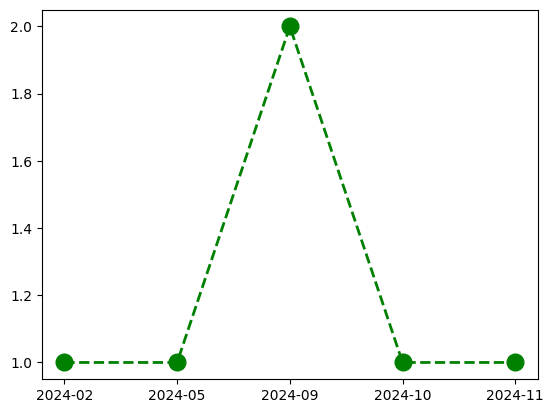

In [96]:
# monthly churn trend - how many customers have churned each month
#  this is time based chart 
df_visual["cancellation_month"] = df_visual['cancellation_date'].dt.to_period('M')
churn_trend = df_visual[df_visual["churn_flag"] == 1].groupby('cancellation_month').size()
plt.plot(churn_trend.index.astype(str), churn_trend.values, color='green', marker='o', linestyle='dashed', linewidth=2, markersize=12)
